In [1]:
import os
import sys

# necessary to make functions available
# Jupyter server should be running from src/python
sys.path.append(
    os.getcwd()
)

In [2]:
import os

import polars as pl

import synapseclient

from feature_distribution_plots import (
    two_group_ridge
)
from colors import COLORS


In [3]:
# Jupyter server should be running from src/python
FIGURE_DIR = os.path.join(
    os.path.dirname(os.path.dirname(os.getcwd())),
    "analysis",
    "mutations",
    "_figures",
    "cell_state"
)

# synapse IDs
META_CACHE_SYNID = "syn74775994"
COMBINED_CACHE_SYNID = "syn74775996"
LIMMA_RESULTS_SYNID = "syn78408378"
GSEA_RESULTS_SYNID = "syn78432275"

In [4]:
os.makedirs(FIGURE_DIR, exist_ok=True)

In [5]:
# Jupyter server should be running from src/python
# assumes auth_token.txt exists in src/python as described in setup instructions
AUTH_TOKEN = os.path.abspath("auth_token.txt")

with open(AUTH_TOKEN, "r") as atf:
    SYN = synapseclient.login(authToken=atf.read())


UPGRADE AVAILABLE

A more recent version of the Synapse Client (4.15.0) is available. Your version (4.11.0) can be upgraded by typing:
   pip install --upgrade synapseclient

Python Synapse Client version 4.15.0 release notes

https://python-docs.synapse.org/news/


Welcome, dylan.ross!



In [6]:
# load sample metadata and combined omics data
meta = pl.read_parquet(SYN.get(META_CACHE_SYNID).path)
combined = pl.read_parquet(SYN.get(COMBINED_CACHE_SYNID).path)

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_75432/3218487284.py:2: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  meta = pl.read_parquet(SYN.get(META_CACHE_SYNID).path)



[syn74775994:metadata.parquet]: Found existing file at /Users/dylan.ross/Projects/AML_outcome_disparities/261016_diffex_overview/diffex_overview/aml_outcome_disparities/analysis/mutations/_cache/metadata.parquet, skipping download.


[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_75432/3218487284.py:3: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  combined = pl.read_parquet(SYN.get(COMBINED_CACHE_SYNID).path)



[syn74775996:combined_omics_data.parquet]: Found existing file at /Users/dylan.ross/Projects/AML_outcome_disparities/261016_diffex_overview/diffex_overview/aml_outcome_disparities/analysis/mutations/_cache/combined_omics_data.parquet, skipping download.


In [7]:
# load limma and gsea results
limma = pl.read_parquet(SYN.get(LIMMA_RESULTS_SYNID).path)
gsea = pl.read_parquet(SYN.get(GSEA_RESULTS_SYNID).path)

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_75432/1942229129.py:2: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  limma = pl.read_parquet(SYN.get(LIMMA_RESULTS_SYNID).path)



[syn78408378:limma_results.parquet]: Found existing file at /Users/dylan.ross/Projects/AML_outcome_disparities/261016_diffex_overview/diffex_overview/aml_outcome_disparities/analysis/mutations/_cache/limma/limma_results.parquet, skipping download.


[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_75432/1942229129.py:3: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  gsea = pl.read_parquet(SYN.get(GSEA_RESULTS_SYNID).path)



[syn78432275:gsea_results.parquet]: Found existing file at /Users/dylan.ross/.synapseCache/383/178910383/gsea_results.parquet, skipping download.


In [8]:
# create a table for selecting out sets of individual features
features = (
    combined.unpivot(
        index=["OmicsType", "Feature"],
        variable_name="Sample",
        value_name="Signal"
    )
    .filter(pl.col("Signal").is_not_null())
    .join(
        meta, on="Sample", how="left"
    )
)

features

OmicsType,Feature,Sample,Signal,Age,Sex,Race,Study,FLT3_ITD,NPM1
str,str,str,f64,f64,str,str,str,bool,bool
"""Acetylomics""","""ACAA2-K234k""","""11-00261""",-2.79,74.0,"""Male""","""White""","""BeatAML""",true,false
"""Acetylomics""","""ACAD9-K202k""","""11-00261""",-0.195,74.0,"""Male""","""White""","""BeatAML""",true,false
"""Acetylomics""","""ACADM-K304k""","""11-00261""",-0.129,74.0,"""Male""","""White""","""BeatAML""",true,false
"""Acetylomics""","""ACADVL-K278k""","""11-00261""",0.272,74.0,"""Male""","""White""","""BeatAML""",true,false
"""Acetylomics""","""ACADVL-K298k""","""11-00261""",-0.622,74.0,"""Male""","""White""","""BeatAML""",true,false
…,…,…,…,…,…,…,…,…,…
"""Phosphoproteomics""","""ZYX-S281s""","""17-00881-Bridge""",-1.342814,76.0,"""Female""","""White""","""pilotStudy""",false,false
"""Phosphoproteomics""","""ZYX-S308s""","""17-00881-Bridge""",-1.989973,76.0,"""Female""","""White""","""pilotStudy""",false,false
"""Phosphoproteomics""","""ZYX-S344s""","""17-00881-Bridge""",-0.039027,76.0,"""Female""","""White""","""pilotStudy""",false,false


## cell state markers

In [9]:
tumor_gene_sets = {
    "HSC-like": [
        "NPTX2", "H1F0", "EMP1", "MEIS1", "CALCRL", "TPSD1", "TPT1", "CRHBP", "CLNK", "TSC22D1", 
        "DST", "NRIP1", "ABCB1", "GABRA4", "ZBTB20", "ABCA9", "TPSB2", "KMT2A", "FAM30A", "MEF2C", 
        "TMEM74", "PDZRN4", "ST3GAL1", "XIRP2", "RBPMS", "TMEM25", "C20orf203", "GNG11", "SLC6A13", "HOPX", 
        "CMTM2", "HIST1H2BK", "NPDC1", "SCRN1", "MECOM", "CXCL2", "CCS", "FAM74A4", "UMODL1-AS1", "CCDC18-AS1", 
        "TTLL10", "CFAP61", "PLCB4", "SPON1", "LINC01770", "CACNB4", "CCDC144NL-AS1", "RNF217", "ZPBP", "MPPED2",
    ],
    "Prog-like": [
        "CDK6", "HSP90AB1", "SPINK2", "EEF1B2", "PCNP", "TAPT1-AS1", "HINT1", "LRRC75A-AS1", "DSE", "PEBP1", 
        "LOC107984974", "H2AFY", "EEF1A1", "SMIM24", "PSME1", "SOX4", "LINC01623", "EEF1G", "EBPL", "EIF4B", 
        "PARP1", "MEST", "TMEM70", "TFDP2", "ATP5G2", "NAP1L1", "MSI2", "TPM4", "SPN", "SELL", 
        "RACK1", "CTSC", "PRDX6", "EGFL7", "SNHG6", "NOP53", "MRPL57", "SELENOP", "CCDC152", "SRSF6", 
        "SNHG8", "B4GALT6", "HNRNPA1", "KIF2A", "HSH2D", "PTPRCAP", "NACA2", "PDLIM1", "CPA3", "GNPTAB",
    ],
    "GMP-like": [
        "PRTN3", "MPO", "CALR", "CLEC5A", "ELANE", "POU4F1", "TRH", "TSPOAP1", "CEBPE", "LINC01835", 
        "NUCB2", "CSF3R", "RUNX1T1", "CD38", "PLPPR3", "IGFBP2", "PRRT4", "SNHG5", "FABP5", "LOC100419170", 
        "CLEC11A", "SERPINB1", "AZU1", "FBN2", "HNRNPDL", "HSPB1", "RNA5-8S", "THSD7A", "C12orf57", "FGFR1", 
        "LPO", "MGST1", "C1QTNF4", "HMGN1", "SIPA1L2", "DDOST", "PTGIR", "GATM", "VAMP8", "FAM46A", 
        "VAMP5", "STAR", "ANKRD18A", "TM7SF3", "CCND1", "ROBO1", "GFI1", "DEFA4", "CERS6", "PTMA",
    ],
    "proMono-like": [
        "DEFB1", "RNASE2", "MS4A3", "SERPINB10", "SESN3", "ZFR", "MRPL33", "CTSG", "SLC44A1", "SLPI", 
        "FUT4", "SRGN", "CD70", "PRLR", "PLD3", "LPL", "RETN", "TP53INP2", "HSPA5", "RNASE3", 
        "CCL23", "EMB", "ATP8B4", "CLU", "FAM107B", "KBTBD11", "CSTA", "ANKRD28", "PIWIL4", "RNVU1-6", 
        "F13A1", "PROK2", "IL31RA", "PLAC8", "ELF1", "EP400NL", "EAF2", "RFX8", "PTGFR", "JUN", 
        "FRMD3", "HOXB-AS3", "PHACTR3", "AK2", "ECRP", "DDIT3", "RFLNB", "FEZ1", "SERPINB2", "CDKN2A", 
    ],
    "Mono-like": [
        "FCN1", "S100A12", "MAFB", "VCAN", "S100A9", "PLBD1", "SERPINA1", "BCL2A1", "THBS1", "PSAP", 
        "S100A8", "FPR1", "C5AR1", "CD14", "NAMPT", "VNN2", "CTSS", "DUSP1", "CEBPB", "CR1", 
        "NFKBIA", "SLC11A1", "LILRB3", "BCL6", "CYP1B1", "TNFAIP2", "MS4A10", "AQP9", "TLR4", "APOBEC3A", 
        "LRRK2", "CD163", "LRP1", "S100A10", "CD68", "MEGF9", "NCF2", "LOC643802", "IFNGR1", "FTL", 
        "SLC24A4", "CD300E", "CXCL8", "CLEC7A", "NEAT1", "CLEC4E", "CRISPLD2", "MEFV", "ACSL1", "NCF1", 
    ],
    "cDC-like": [
        "MRC1", "HLA-DRB5", "CST3", "SAMHD1", "NAPSB", "FCER1A", "HLA-DRB1", "JAML", "PKIB", "HLA-DRA", 
        "HLA-DRB6", "CPVL", "HLA-DPB1", "HLA-DQA1", "HLA-DPA1", "CLEC4A", "TMSB10", "CAP1", "HLA-DQB1", "CRIP1", 
        "CLEC10A", "GPX1", "ITGB7", "HLA-DQB2", "DBI", "FTH1P3", "ACTB", "HLA-DQA2", "S100B", "ALDH2", 
        "GABARAP", "LY86", "IGSF6", "HLA-DPB2", "CD74", "PAK1", "LGALS2", "CSF1R", "PALLD", "CCR2", 
        "GPR183", "GRB2", "EPS8", "COTL1", "DHRS9", "HLA-DMB", "HLA-DMA", "PYCARD", "LOC644936", "SH3BGRL3", 
    ]
}

In [10]:
# collect average expression for all of the gene sets into a data frame
# the expression levels of all individual gene set members are first 
# z-score normalized, then we take the mean across the gene set for each sample
# we do this separately for samples in both race groups
cell_types = {
    race: pl.DataFrame(
        [
            [
                gs,
                (
                    features
                    .filter(
                        (pl.col("Race") == race)
                        & (pl.col("OmicsType") == "Transcriptomics")
                        & (pl.col("Feature").is_in(tumor_gene_sets[gs][:30]))
                        & ~pl.col("FLT3_ITD")
                    )
                    .group_by("Feature")
                    .agg(
                        "Signal",
                        "Sample",
                        "NPM1"
                    )
                    .with_columns(
                        pl.col("Signal").list.mean().alias("Signal_mean"),
                        pl.col("Signal").list.std().alias("Signal_std")
                    )
                    .with_columns(
                        ((pl.col("Signal") - pl.col("Signal_mean")) / pl.col("Signal_std")).alias("Z")
                    )
                    .drop("Signal", "Signal_mean", "Signal_std")
                    .explode("Sample", "NPM1", "Z")
                    .filter(~pl.col("NPM1"))
                    .group_by("Sample")
                    .agg(pl.col("Z").mean())
                    ["Z"]
                    .to_list()
                ),
                (
                    features
                    .filter(
                        (pl.col("Race") == race)
                        & (pl.col("OmicsType") == "Transcriptomics")
                        & (pl.col("Feature").is_in(tumor_gene_sets[gs][:30]))
                        & ~pl.col("FLT3_ITD")
                    )
                    .group_by("Feature")
                    .agg(
                        "Signal",
                        "Sample",
                        "NPM1"
                    )
                    .with_columns(
                        pl.col("Signal").list.mean().alias("Signal_mean"),
                        pl.col("Signal").list.std().alias("Signal_std")
                    )
                    .with_columns(
                        ((pl.col("Signal") - pl.col("Signal_mean")) / pl.col("Signal_std")).alias("Z")
                    )
                    .drop("Signal", "Signal_mean", "Signal_std")
                    .explode("Sample", "NPM1", "Z")
                    .filter(pl.col("NPM1"))
                    .group_by("Sample")
                    .agg(pl.col("Z").mean())
                    ["Z"]
                    .to_list()
                ),
                
            ]
            for gs
            in [
                "HSC-like", "Prog-like", "GMP-like", 
                "proMono-like", "Mono-like", "cDC-like"
            ]
        ], schema=["feature", "A", "B"], orient="row").with_row_index()
    for race in ["Black", "White"]
}

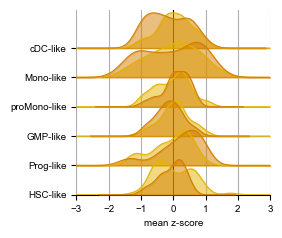

In [43]:
two_group_ridge(
    cell_types["White"],
    COLORS.WHITE_WT,
    COLORS.WHITE_NPM1,
    x_min=-3, x_max=3,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.5,
    xlabel="mean z-score",
    figname=os.path.join(FIGURE_DIR, "cell_scores_white_npm1+-.png"),
)

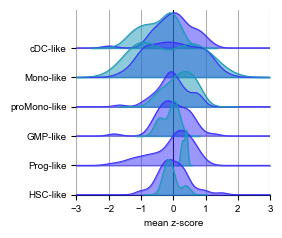

In [44]:
two_group_ridge(
    cell_types["Black"],
    COLORS.BLACK_WT,
    COLORS.BLACK_NPM1,
    x_min=-3, x_max=3,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.5,
    xlabel="mean z-score",
    figname=os.path.join(FIGURE_DIR, "cell_scores_black_npm1+-.png"),
)

## utility

In [45]:
def make_dz_df(features, genes, race, omics_type):
    return (
        pl.DataFrame([
        (
            g, 
            (
                features
                .filter(
                    (pl.col("Race") == race)
                    & (pl.col("OmicsType") == omics_type)
                    & (pl.col("Feature") == g)
                    & ~pl.col("FLT3_ITD")
                )
                .group_by("Feature")
                .agg(
                    "Signal",
                    "Sample",
                    "NPM1"
                )
                .with_columns(
                    pl.col("Signal").list.mean().alias("Signal_mean"),
                    pl.col("Signal").list.std().alias("Signal_std")
                )
                .with_columns(
                    ((pl.col("Signal") - pl.col("Signal_mean")) / pl.col("Signal_std")).alias("Z")
                )
                .drop("Signal", "Signal_mean", "Signal_std")
                .explode("Sample", "NPM1", "Z")
                .filter(~pl.col("NPM1"))
                ["Z"]
                .to_list()
            ),
            (
                features
                .filter(
                    (pl.col("Race") == race)
                    & (pl.col("OmicsType") == omics_type)
                    & (pl.col("Feature") == g)
                    & ~pl.col("FLT3_ITD")
                )
                .group_by("Feature")
                .agg(
                    "Signal",
                    "Sample",
                    "NPM1"
                )
                .with_columns(
                    pl.col("Signal").list.mean().alias("Signal_mean"),
                    pl.col("Signal").list.std().alias("Signal_std")
                )
                .with_columns(
                    ((pl.col("Signal") - pl.col("Signal_mean")) / pl.col("Signal_std")).alias("Z")
                )
                .drop("Signal", "Signal_mean", "Signal_std")
                .explode("Sample", "NPM1", "Z")
                .filter(pl.col("NPM1"))
                ["Z"]
                .to_list()
            )
        )
        for g
        in genes
    ], schema=["feature", "A", "B"], orient="row").with_row_index()
    )

## MHC class II

In [46]:
mhc_ii = ["HLA-DRB1", "HLA-DRB5", "HLA-DRA", "HLA-DPB1", "HLA-DPA1"]

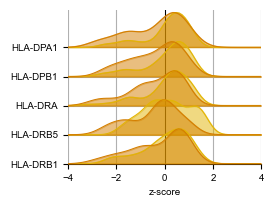

In [47]:
two_group_ridge(
    make_dz_df(features, mhc_ii, "White", "Transcriptomics"),
    COLORS.WHITE_WT,
    COLORS.WHITE_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.5,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "mhcii_white_npm1+-_tx.png"),
)

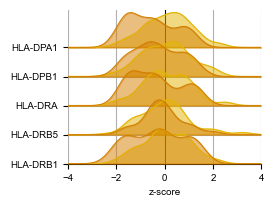

In [48]:
two_group_ridge(
    make_dz_df(features, mhc_ii, "White", "Proteomics"),
    COLORS.WHITE_WT,
    COLORS.WHITE_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.5,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "mhcii_white_npm1+-_px.png"),
)

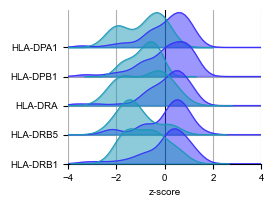

In [49]:
two_group_ridge(
    make_dz_df(features, mhc_ii, "Black", "Transcriptomics"),
    COLORS.BLACK_WT,
    COLORS.BLACK_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.5,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "mhcii_black_npm1+-_tx.png"),
)

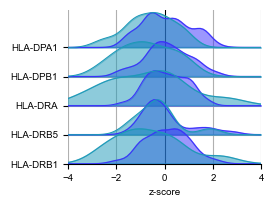

In [50]:
two_group_ridge(
    make_dz_df(features, mhc_ii, "Black", "Proteomics"),
    COLORS.BLACK_WT,
    COLORS.BLACK_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.5,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "mhcii_black_npm1+-_px.png"),
)

## neutrophil maturation

In [19]:
neu_tf = [
    "IRF8", "CEBPA",    # (TF) GMP
    "GFI1",             # (TF) GMP + preNeu
    "CEBPE",            # (TF) preNeu + immNeu
    "CEBPD",            # (TF) matNeu
]

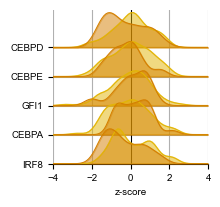

In [32]:
two_group_ridge(
    make_dz_df(features, neu_tf, "White", "Proteomics"),
    COLORS.WHITE_WT,
    COLORS.WHITE_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "neu_tf_white_npm1+-_px.png"),
)

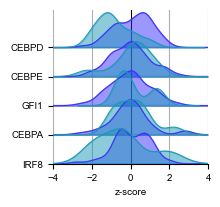

In [31]:
two_group_ridge(
    make_dz_df(features, neu_tf, "Black", "Proteomics"),
    COLORS.BLACK_WT,
    COLORS.BLACK_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "neu_tf_black_npm1+-_px.png"),
)

In [22]:
neu_surf = [
    "CD38",     # (CS) preNeu
    "CXCR4",    # (CS) immNeu
    "CD33",     # (CS) preNeu + immNeu + matNeu
    "CD101",    # (CS) immNeu + matNeu
    "CD44",     # (CS) matNeu
]

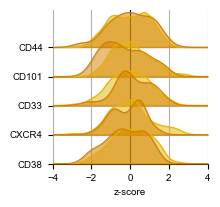

In [33]:
two_group_ridge(
    make_dz_df(features, neu_surf, "White", "Proteomics"),
    COLORS.WHITE_WT,
    COLORS.WHITE_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "neu_surf_white_npm1+-_px.png"),
)

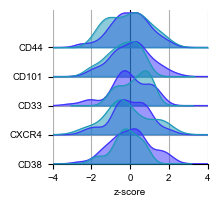

In [34]:
two_group_ridge(
    make_dz_df(features, neu_surf, "Black", "Proteomics"),
    COLORS.BLACK_WT,
    COLORS.BLACK_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "neu_surf_black_npm1+-_px.png"),
)

In [25]:
neu_grn = [
    "HEXA",                             # (G1) GMP
    "PRSS57", "PRTN3", "CTSG",          # (G1) GMP + preNeu
    "CTSC",                             # (G1) GMP + immNeu
    "HEXB",                             # (G1) preNeu + immNeu
    "LTF", "CAMP", "CYBB", "CEACAM1",   # (G2) preNeu + immNeu
    "LCN2", "LYZ",                      # (G2) preNeu + immNeu + matNeu
    "ITGAM",                            # (G3) preNeu + immNeu + matNeu
    "HP",                               # (G2) matNeu
    "CFP", "ADAM8"                      # (G3) matNeu
]

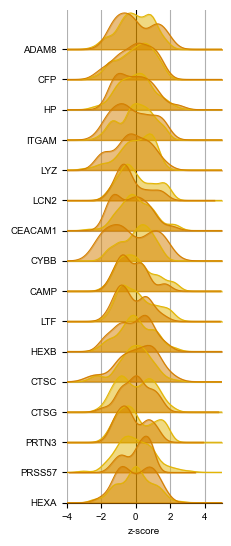

In [42]:
two_group_ridge(
    make_dz_df(features, neu_grn, "White", "Proteomics"),
    COLORS.WHITE_WT,
    COLORS.WHITE_NPM1,
    x_min=-4, x_max=5,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "neu_grn_white_npm1+-_px.png"),
)

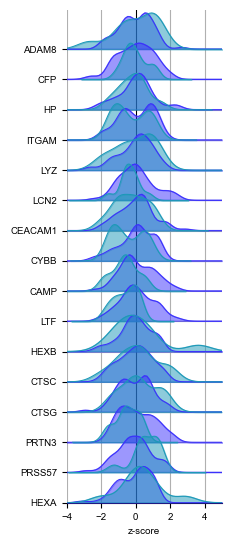

In [41]:
two_group_ridge(
    make_dz_df(features, neu_grn, "Black", "Proteomics"),
    COLORS.BLACK_WT,
    COLORS.BLACK_NPM1,
    x_min=-4, x_max=5,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "neu_grn_black_npm1+-_px.png"),
)

## HOX

In [28]:
hox = [
    "HOXA5", "HOXA6", "HOXA7", "HOXA9", "HOXA10",
    "HOXB3", "HOXB4", "HOXB5", "HOXB6",
    "MEIS1", "PBX3", 
]

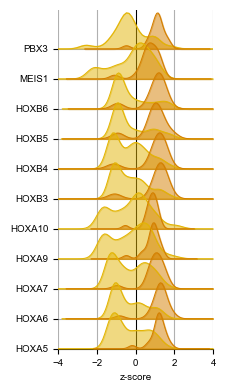

In [35]:
two_group_ridge(
    make_dz_df(features, hox, "White", "Transcriptomics"),
    COLORS.WHITE_WT,
    COLORS.WHITE_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "hox_white_npm1+-_tx.png"),
)

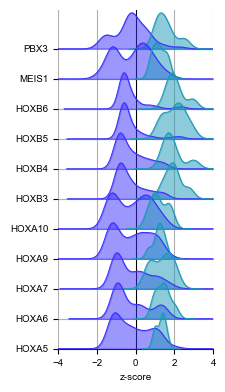

In [36]:
two_group_ridge(
    make_dz_df(features, hox, "Black", "Transcriptomics"),
    COLORS.BLACK_WT,
    COLORS.BLACK_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "hox_black_npm1+-_tx.png"),
)

## Double check what features limma says are significant
filter on unadjusted p-value because we are looking at these "indivdually"

### MHC class II

In [71]:
# BvB, WvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_Black_NPM1-/FLT3-ITD-",
            "White_NPM1+/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-",
        ]))
        & (pl.col("OmicsType") == "Transcriptomics")
        & (pl.col("Feature").is_in(mhc_ii))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""HLA-DRA""",-1.674777,0.030936,0.28249,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HLA-DPA1""",-1.774568,0.028818,0.273177,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HLA-DPB1""",-1.639618,0.035293,0.297933,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HLA-DRB5""",-2.749151,0.001284,0.079233,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HLA-DRB1""",-1.545754,0.044518,0.326156,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HLA-DRB5""",-1.050888,0.038023,0.298833,"""White_NPM1+/FLT3-ITD-_vs_White…"


In [72]:
# BvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_White_NPM1+/FLT3-ITD-",
            "Black_NPM1-/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-"
        ]))
        & (pl.col("OmicsType") == "Transcriptomics")
        & (pl.col("Feature").is_in(mhc_ii))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str


### neutrophil maturation (transcription factors)

In [73]:
# BvB, WvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_Black_NPM1-/FLT3-ITD-",
            "White_NPM1+/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-",
        ]))
        & (pl.col("OmicsType") == "Proteomics")
        & (pl.col("Feature").is_in(neu_tf))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""CEBPD""",-0.9526,0.00759,0.679348,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""IRF8""",-0.592066,0.028949,0.999894,"""White_NPM1+/FLT3-ITD-_vs_White…"


In [74]:
# BvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_White_NPM1+/FLT3-ITD-",
            "Black_NPM1-/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-"
        ]))
        & (pl.col("OmicsType") == "Proteomics")
        & (pl.col("Feature").is_in(neu_tf))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""CEBPA""",-0.334072,0.020346,0.043615,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CEBPD""",-0.834091,0.000001,0.000019,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CEBPE""",-0.426892,0.015862,0.035483,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""GFI1""",-0.276572,0.031922,0.063116,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""IRF8""",-0.531231,0.005583,0.014824,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CEBPD""",-1.372769,0.000545,0.280145,"""Black_NPM1+/FLT3-ITD-_vs_White…"


### neutrophil maturation (cell surface markers)

In [75]:
# BvB, WvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_Black_NPM1-/FLT3-ITD-",
            "White_NPM1+/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-",
        ]))
        & (pl.col("OmicsType") == "Proteomics")
        & (pl.col("Feature").is_in(neu_surf))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str


In [76]:
# BvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_White_NPM1+/FLT3-ITD-",
            "Black_NPM1-/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-"
        ]))
        & (pl.col("OmicsType") == "Proteomics")
        & (pl.col("Feature").is_in(neu_surf))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""CD101""",-0.709965,0.000017,0.000142,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CD33""",-0.452176,0.006118,0.015963,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CD38""",-0.428769,0.003388,0.009878,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CD44""",-0.458074,0.001117,0.004003,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CXCR4""",-0.389671,0.009029,0.022157,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CD101""",-0.804516,0.034522,0.286704,"""Black_NPM1+/FLT3-ITD-_vs_White…"


### neutrophil maturation (granule proteins)

In [77]:
# BvB, WvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_Black_NPM1-/FLT3-ITD-",
            "White_NPM1+/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-",
        ]))
        & (pl.col("OmicsType") == "Proteomics")
        & (pl.col("Feature").is_in(neu_grn))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""CAMP""",-1.383096,0.014524,0.879503,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""LTF""",-0.952976,0.045026,0.999835,"""Black_NPM1+/FLT3-ITD-_vs_Black…"


In [81]:
# BvW
with pl.Config(set_tbl_rows=20):
    display(
        limma
        .filter(
            (pl.col("Contrast").is_in([
                "Black_NPM1+/FLT3-ITD-_vs_White_NPM1+/FLT3-ITD-",
                "Black_NPM1-/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-"
            ]))
            & (pl.col("OmicsType") == "Proteomics")
            & (pl.col("Feature").is_in(neu_grn))
            & (pl.col("P.Value") <= 0.05)
        )
        .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
    )

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""ADAM8""",-0.650473,0.000014,0.000123,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CEACAM1""",-0.599166,0.002778,0.008374,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CFP""",-0.621424,0.000194,0.000962,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CTSC""",-0.319488,0.010446,0.024959,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CTSG""",-1.024271,0.000124,0.000675,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""CYBB""",-0.845944,0.000128,0.000693,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""HEXA""",-0.447554,0.000477,0.00199,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""HEXB""",-0.703212,0.000002,0.000031,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""HP""",-0.531449,0.004169,0.011669,"""Black_NPM1-/FLT3-ITD-_vs_White…"


### HOX

In [82]:
# BvB, WvW
with pl.Config(set_tbl_rows=25):
    display(
        limma
        .filter(
            (pl.col("Contrast").is_in([
                "Black_NPM1+/FLT3-ITD-_vs_Black_NPM1-/FLT3-ITD-",
                "White_NPM1+/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-",
            ]))
            & (pl.col("OmicsType") == "Transcriptomics")
            & (pl.col("Feature").is_in(hox))
            & (pl.col("P.Value") <= 0.05)
        )
        .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
    )

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""MEIS1""",4.190259,0.000208,0.030377,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HOXA9""",3.589029,0.000277,0.036164,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HOXA5""",3.533924,0.000055,0.013726,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HOXB3""",4.784651,1.1565e-7,0.000111,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""PBX3""",2.879278,3.3538e-7,0.000273,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HOXA10""",3.053887,0.000228,0.031895,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HOXA6""",3.627817,0.000005,0.002477,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HOXB4""",4.033463,2.0318e-7,0.000182,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""HOXA7""",3.171051,0.000032,0.010395,"""Black_NPM1+/FLT3-ITD-_vs_Black…"


In [80]:
# BvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_White_NPM1+/FLT3-ITD-",
            "Black_NPM1-/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-"
        ]))
        & (pl.col("OmicsType") == "Transcriptomics")
        & (pl.col("Feature").is_in(hox))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""MEIS1""",-1.008631,0.035745,0.17647,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""PBX3""",-0.736831,0.001931,0.031496,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""HOXB4""",-0.809835,0.012696,0.099808,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""HOXB6""",-0.938394,0.007853,0.075074,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""HOXB5""",-0.778085,0.013872,0.103982,"""Black_NPM1-/FLT3-ITD-_vs_White…"
